### 1. Φόρτωση και Διαχωρισμός Ιστορικών Ατομικών Ρεκόρ (400m vs 200m)

In [72]:
# Φόρτωση του αρχείου clean_records.csv (2003–2026) και διαχωρισμός των ρεκόρ
# σε κατηγορίες 400m και 200m (<200>), εξαιρώντας τις παιδικές κατηγορίες 100m (<100>).

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

records = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_records.csv"))

# Απομόνωση καθαρών ρεκόρ 400m (Αυτοκίνητο & Μηχανή)
rec_400 = records[
    (records['Απόσταση_Ρεκόρ_m'] == 400) &
    (~records['Περιγραφή'].astype(str).str.contains('<100', na=False)) &
    (records['Τύπος_Οχήματος_Ονομα'].isin(['Αυτοκίνητο', 'Μηχανή'])) &
    (records['Χρόνος400'] > 5.5)
].copy()

# Απομόνωση καθαρών ρεκόρ 200m (<200>)
rec_200 = records[
    (records['Απόσταση_Ρεκόρ_m'] == 200) &
    (records['Τύπος_Οχήματος_Ονομα'].isin(['Αυτοκίνητο', 'Μηχανή'])) &
    (records['Χρόνος400'] > 3.5)
].copy()

print(f"Σύνολο Ιστορικών Ρεκόρ (2003–2026): {len(records)}")
print(f" -> Ρεκόρ 400m (Αυτοκίνητο & Μηχανή): {len(rec_400)} (Αυτοκίνητα: {(rec_400['Τύπος_Οχήματος_Ονομα']=='Αυτοκίνητο').sum()}, Μηχανές: {(rec_400['Τύπος_Οχήματος_Ονομα']=='Μηχανή').sum()})")
print(f" -> Ρεκόρ 200m (Αυτοκίνητο & Μηχανή): {len(rec_200)}")

Σύνολο Ιστορικών Ρεκόρ (2003–2026): 2488
 -> Ρεκόρ 400m (Αυτοκίνητο & Μηχανή): 2273 (Αυτοκίνητα: 797, Μηχανές: 1476)
 -> Ρεκόρ 200m (Αυτοκίνητο & Μηχανή): 195


### 2. Συγκριτικά Περιγραφικά Στατιστικά (Count, Mean, Median, Std, Min, Max)
- #### Όπως βλέπεις από το Count, υπάρχουν μέσα στο records table μερικά περάσματα που έχουν χρόνο στα 400 αλλά δεν έχουν ταχύτητα (κρατάμε ΜΟΝΟ τον χρόνο και κάνουμε filter out την outlier (μηδενική) ταχύτητα <80).

In [73]:
# Υπολογισμός βασικών περιγραφικών στατιστικών (Count, Mean, Median, Std, Min, Max)
# για τους χρόνους (ET) και τις ταχύτητες εξόδου των Ρεκόρ ανά Τύπο Οχήματος.

def calc_stats(series):
    return pd.Series({
        'Count (Πλήθος)': series.count(),
        'Mean (Μέσος Όρος)': series.mean(),
        'Median (Διάμεσος)': series.median(),
        'Std (Τυπ. Απόκλιση)': series.std(),
        'Min (Ελάχιστο)': series.min(),
        'Max (Μέγιστο)': series.max()
    }).round(3)

cars_400 = rec_400[rec_400['Τύπος_Οχήματος_Ονομα'] == 'Αυτοκίνητο']
bikes_400 = rec_400[rec_400['Τύπος_Οχήματος_Ονομα'] == 'Μηχανή']

rec_stats_df = pd.DataFrame({
    'Αυτοκίνητο 400m ET (s)': calc_stats(cars_400['Χρόνος400']),
    'Μηχανή 400m ET (s)': calc_stats(bikes_400['Χρόνος400']),
    '200m (<200>) ET (s)': calc_stats(rec_200['Χρόνος400']),
    'Αυτοκίνητο Ταχ. 400m (km/h)': calc_stats(cars_400[cars_400['Ταχύτητα400'] > 80]['Ταχύτητα400']),
    'Μηχανή Ταχ. 400m (km/h)': calc_stats(bikes_400[bikes_400['Ταχύτητα400'] > 80]['Ταχύτητα400'])
})

display(rec_stats_df)

,Αυτοκίνητο 400m ET (s),Μηχανή 400m ET (s),200m (<200>) ET (s),Αυτοκίνητο Ταχ. 400m (km/h),Μηχανή Ταχ. 400m (km/h)
Count (Πλήθος),797.000,1476.000,195.000,786.000,1439.000
Mean (Μέσος Όρος),12.204,10.336,5.558,188.893,219.813
Median (Διάμεσος),12.110,9.785,5.417,186.345,234.290
Std (Τυπ. Απόκλιση),1.653,1.672,0.967,29.528,39.390
Min (Ελάχιστο),6.747,7.156,4.532,85.880,81.310
Max (Μέγιστο),17.386,20.342,11.806,308.440,290.790


### 3. Πίνακας "Hall of Fame" - Top 5 Ταχύτερα Ρεκόρ 400m Όλων των Εποχών

In [74]:
# Εύρεση των 5 ταχύτερων ρεκόρ 400m όλων των εποχών (2003–2026)
# ξεχωριστά για Αυτοκίνητα και Μηχανές.

cols_show = ['Ετος', 'Ονοματεπώνυμο', 'Οχημα', 'Περιγραφή', 'ΠΙΣΤΑ', 'Χρόνος400', 'Ταχύτητα400']

print("Top 5 Ταχύτερα Ρεκόρ 400m - ΑΥΤΟΚΙΝΗΤΑ:")
display(cars_400.nsmallest(5, 'Χρόνος400')[cols_show])

print("\nTop 5 Ταχύτερα Ρεκόρ 400m - ΜΗΧΑΝΕΣ:")
display(bikes_400.nsmallest(5, 'Χρόνος400')[cols_show])

Top 5 Ταχύτερα Ρεκόρ 400m - ΑΥΤΟΚΙΝΗΤΑ:


,Ετος,Ονοματεπώνυμο,Οχημα,Περιγραφή,ΠΙΣΤΑ,Χρόνος400,Ταχύτητα400
0,2008,ΚΑΤΣΑΦΑΔΟΣ ΒΑΓΓΕΛΗΣ,TOP METHANOL,OPEN,ΠΟΛΥΚΑΣΤΡΟ,6.747,303.42
1,2007,ΠΑΠΑΦΙΛΙΠΠΟΥ ΦΙΛΙΠΠΟΣ,FIL'S LETHAL WEAPON,OPEN,ΠΟΛΥΚΑΣΤΡΟ,7.274,308.44
2,2005,ΝΕΦΡΑΙΜ ΜΑΚΗΣ,PONTIAC,OPEN,ΣΕΡΡΕΣ,8.158,280.75
286,2014,ΦΩΣΚΟΛΟΣ ΝΙΚΟΣ,BMW V8,INDEX 8,ΠΟΛΥΚΑΣΤΡΟ,8.360,277.59
3,2005,ΠΑΣΧΟΣ ΔΗΜΗΤΡΙΟΣ,FORD SIERRA DRAGSTER,OPEN,ΕΛΛΗΝΙΚΟ,8.429,256.78



Top 5 Ταχύτερα Ρεκόρ 400m - ΜΗΧΑΝΕΣ:


,Ετος,Ονοματεπώνυμο,Οχημα,Περιγραφή,ΠΙΣΤΑ,Χρόνος400,Ταχύτητα400
313,2013,ΠΑΠΑΦΙΛΙΠΠΟΥ ΦΙΛΙΠΠΟΣ,SUZUKI 1300,SUPER PRO,ΠΟΛΥΚΑΣΤΡΟ,7.156,280.85
314,2009,ΖΑΦΕΙΡΙΑΔΗΣ ΑΝΤΩΝΗΣ,GABRIEL,SUPER PRO,ΠΟΛΥΚΑΣΤΡΟ,7.412,285.68
318,2015,ΓΚΟΣΙΟΣ ΔΗΜΗΤΡΙΟΣ,SUZUKI TURBO,SUPER PRO,ΠΟΛΥΚΑΣΤΡΟ,7.412,283.49
315,2013,ΜΙΧΑΗΛΙΔΗΣ ΚΩΣΤΑΣ,YAMAHA R1 TURBO,SUPER PRO,ΠΟΛΥΚΑΣΤΡΟ,7.426,267.29
316,2013,ΜΠΟΥΣΙΝΗΣ ΧΑΡΑΛΑΜΠΟΣ,SUZUKI 1640,SUPER PRO,ΠΟΛΥΚΑΣΤΡΟ,7.451,290.79


### 4. Ανάλυση Ατομικών Ρεκόρ ανά Πίστα (ΣΕΡΡΕΣ, ΠΟΛΥΚΑΣΤΡΟ, ΚΩΠΑΪΔΑ, ΕΛΛΗΝΙΚΟ)

In [75]:
# Ομαδοποίηση των ατομικών ρεκόρ 400m ανά Πίστα.
# Δείχνει πόσα ρεκόρ σημειώθηκαν σε κάθε πίστα, την περίοδο ενεργής καταγραφής,
# καθώς και τους ταχύτερους/μέσους χρόνους και ταχύτητες.

track_summary = (
    rec_400.groupby('ΠΙΣΤΑ') # Αν θέλω να ξεχωρίσω Αυτοκίνητο και Μηχανή πρέπει να κάνω .groupby(['ΠΙΣΤΑ', 'Τύπος_Οχήματος_Ονομα'])
    .agg(
        Πλήθος_Ρεκόρ=('Id_Record', 'count'),
        Πρώτο_Έτος=('Ετος', 'min'),
        Τελευταίο_Έτος=('Ετος', 'max'),
        Ταχύτερο_ET_s=('Χρόνος400', 'min'),
        Μέσο_ET_s=('Χρόνος400', 'mean'),
        Διάμεσος_ET_s=('Χρόνος400', 'median'),
        Μέγιστη_Ταχύτητα_kmh=('Ταχύτητα400', 'max'),
        Μέση_Ταχύτητα_kmh=('Ταχύτητα400', 'mean')
    )
    .round(3)
    .sort_values(by='Πλήθος_Ρεκόρ', ascending=False)
)

display(track_summary)

,Πλήθος_Ρεκόρ,Πρώτο_Έτος,Τελευταίο_Έτος,Ταχύτερο_ET_s,Μέσο_ET_s,Διάμεσος_ET_s,Μέγιστη_Ταχύτητα_kmh,Μέση_Ταχύτητα_kmh
ΠΙΣΤΑ,,,,,,,,
ΣΕΡΡΕΣ,1523,2003,2026,7.834,10.934,10.481,283.02,203.926
ΠΟΛΥΚΑΣΤΡΟ,689,2007,2015,6.747,11.157,10.849,308.44,205.261
ΑΕΡ. ΙΚΑΡΟΣ ΚΩΠΑΪΔΑ,50,2016,2016,9.196,10.577,9.944,249.16,211.517
ΕΛΛΗΝΙΚΟ,11,2005,2005,8.429,10.463,10.470,278.41,217.287


### 5. Στατιστικός Έλεγχος Διαχρονικής Τάσης (Spearman Rank Correlation)

In [76]:
# Στατιστικός έλεγχος συσχέτισης Spearman (scipy.stats.spearmanr) μεταξύ Έτους (2003–2026)
# και Επιδόσεων (Χρόνος 400m & Ταχύτητα 400m). Εξετάζει αν οι χρόνοι πέφτουν (αρνητικό r)
# και αν οι ταχύτητες ανεβαίνουν (θετικό r) με την πάροδο των ετών.

trend_results = []
for vtype, sub in [('Αυτοκίνητο', cars_400), ('Μηχανή', bikes_400)]:
    sub_spd = sub[sub['Ταχύτητα400'] > 80] # SOS - We have to filter out again τις μηδενικές ταχύτητες!
    r_et, p_et = stats.spearmanr(sub['Ετος'], sub['Χρόνος400'])
    r_spd, p_spd = stats.spearmanr(sub_spd['Ετος'], sub_spd['Ταχύτητα400'])
    trend_results.append({
        'Τύπος Οχήματος': vtype,
        'Spearman r (Έτος vs ET)': round(r_et, 3),
        'p-value (ET)': round(p_et, 4),
        'Spearman r (Έτος vs Ταχύτητα)': round(r_spd, 3),
        'p-value (Ταχύτητα)': round(p_spd, 4)
    })

trend_df = pd.DataFrame(trend_results)
display(trend_df)

,Τύπος Οχήματος,Spearman r (Έτος vs ET),p-value (ET),Spearman r (Έτος vs Ταχύτητα),p-value (Ταχύτητα)
0,Αυτοκίνητο,-0.081,0.0216,-0.005,0.8954
1,Μηχανή,-0.300,0.0000,0.228,0.0000


### **Τι δείχνει ο στατιστικός έλεγχος (Spearman r):**
- #### Στις Μηχανές: Υπάρχει ισχυρή, στατιστικά σημαντική **πτωτική τάση** στους χρόνους 400m ($r = -0.300, p < 0.0001$) και **ανοδική τάση** στις ταχύτητες εξόδου ($r = +0.228, p < 0.0001$) από το 2004 έως το 2026 (ο διάμεσος χρόνος ρεκόρ έπεσε από τα ~$10.3 s$–$11.0 s$ στα $9.35 s$ το 2026)! *(μπορείς να παρατηρήσεις τις τάσεις αυτές στο 2ο διάγραμμα στο επόμενο κελί)*
- #### Στα Αυτοκίνητα: Η συσχέτιση του έτους με την τελική ταχύτητα (r = -0.005, p = 0.8954) είναι πρακτικά μηδενική και στατιστικά μη σημαντική λόγω του πολύ μεγάλου p-value (>0.05), άρα δεν υπάρχει ένδειξη τάσης στην ταχύτητα των αυτοκινήτων με τα χρόνια. Η συσχέτιση του έτους με τον χρόνο τερματισμού (r = -0.081, p = 0.0216) είναι στατιστικά σημαντική στο επίπεδο 0.05, αλλά το μέγεθός της είναι αμελητέο, οπότε η μείωση των χρόνων με τα χρόνια είναι πολύ μικρή στην πράξη.

### 6. Οπτικοποίηση Ιστορικών Τάσεων

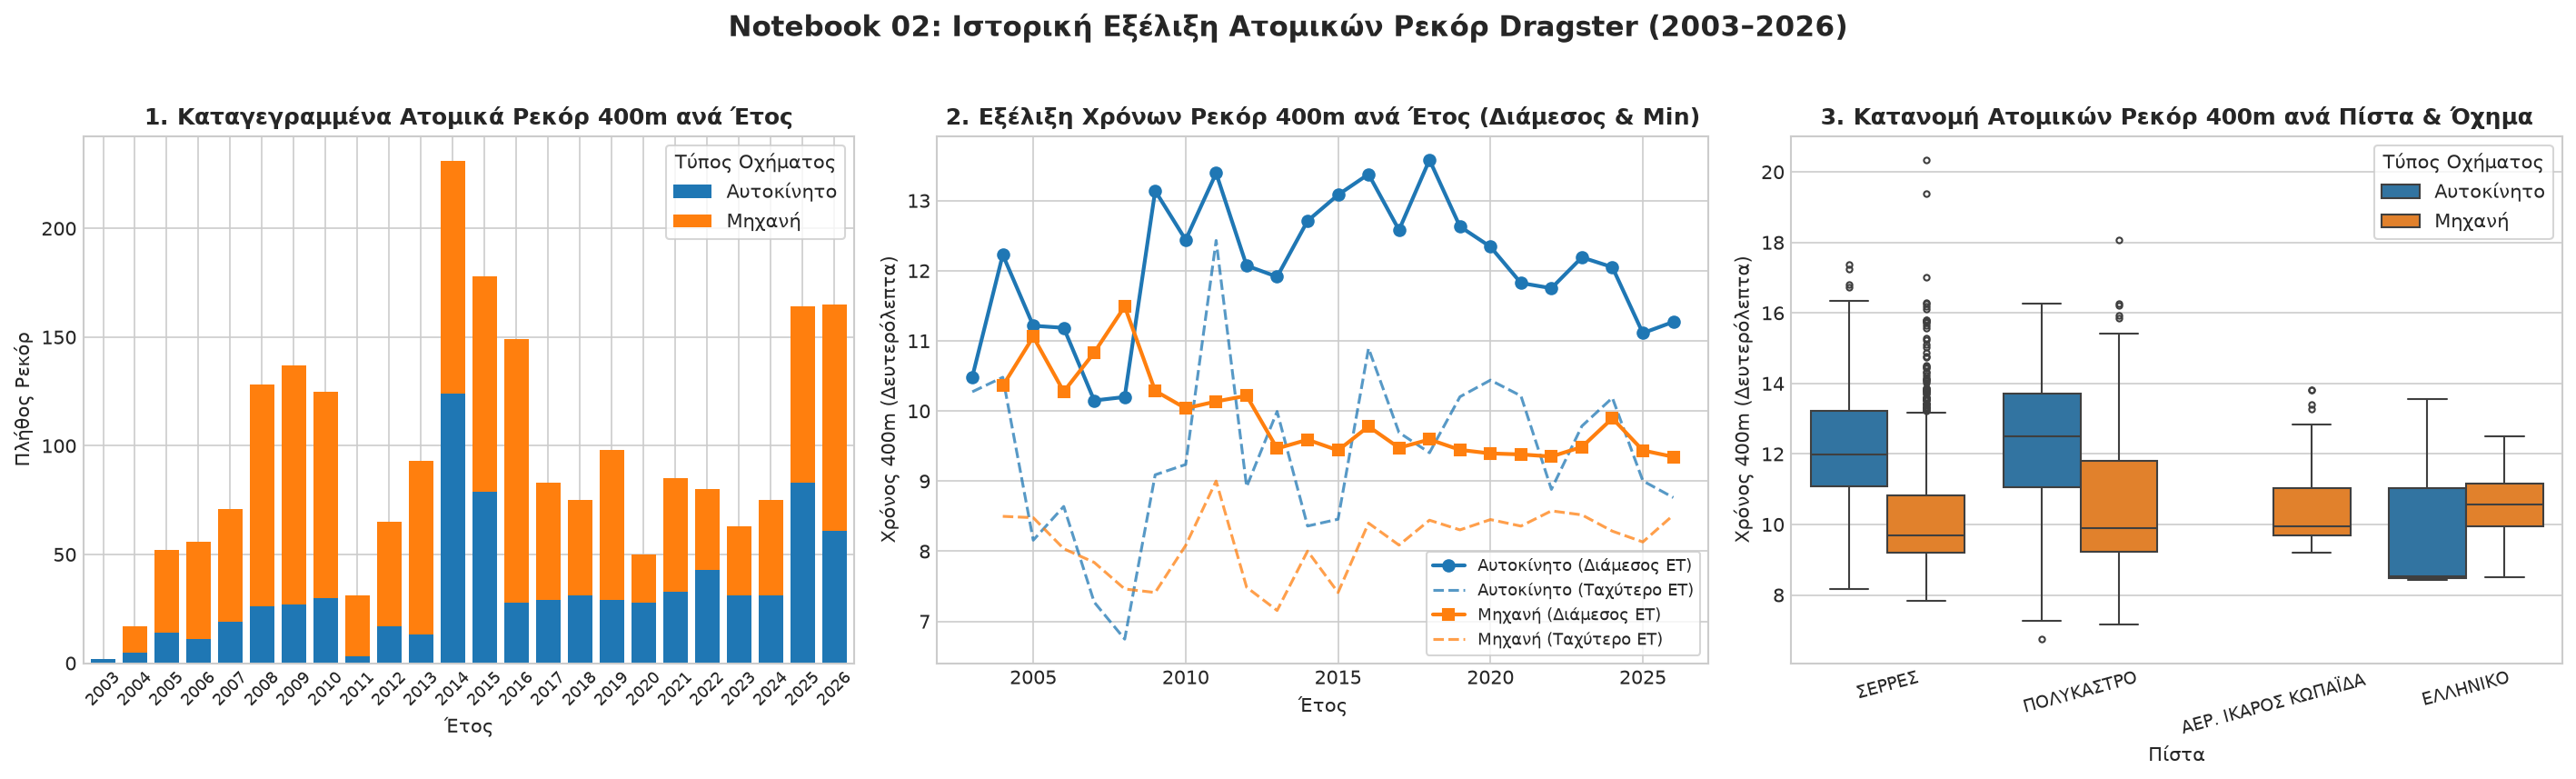

Το γράφημα αποθηκεύτηκε στο: ..\outputs\figures\02_historical_trends.png


In [77]:
# Δημιουργία τριπλού γραφήματος ιστορικής ανάλυσης (2003–2026):
# (1) Πλήθος καταγεγραμμένων ρεκόρ 400m ανά Έτος και Τύπο Οχήματος,
# (2) Διαχρονική εξέλιξη Διάμεσου και Ταχύτερου (Min) χρόνου 400m ανά Έτος,
# (3) Boxplot κατανομής χρόνων 400m ανά Πίστα και Τύπο Οχήματος.

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=150)
fig.suptitle('Notebook 02: Ιστορική Εξέλιξη Ατομικών Ρεκόρ Dragster (2003–2026)', fontsize=15, fontweight='bold', y=1.03)

# 1. Stacked Bar Chart: Πλήθος Ρεκόρ ανά Έτος
ax1 = axes[0]
yearly_counts = rec_400.pivot_table(
    index='Ετος', columns='Τύπος_Οχήματος_Ονομα', values='Id_Record', aggfunc='count', fill_value=0
)
yearly_counts.plot(kind='bar', stacked=True, ax=ax1, color=['#1f77b4', '#ff7f0e'], width=0.75) # Το index του πίνακα γίνεται ο άξονας x και κάθε στήλη γίνεται μία σειρά (στρώμα) με ύψη στον άξονα y.
ax1.set_title('1. Καταγεγραμμένα Ατομικά Ρεκόρ 400m ανά Έτος', fontsize=12, fontweight='bold')
ax1.set_xlabel('Έτος')
ax1.set_ylabel('Πλήθος Ρεκόρ')
ax1.tick_params(axis='x', rotation=45, labelsize=8.5)
ax1.legend(title='Τύπος Οχήματος', frameon=True, fontsize=10)

# 2. Line Chart: Εξέλιξη Διάμεσου & Ταχύτερου Χρόνου 400m ανά Έτος
ax2 = axes[1]
yearly_et = rec_400.groupby(['Ετος', 'Τύπος_Οχήματος_Ονομα'])['Χρόνος400'].agg(['min', 'median']).reset_index()

for vtype, color, marker in [('Αυτοκίνητο', '#1f77b4', 'o'), ('Μηχανή', '#ff7f0e', 's')]: # o --> κύκλος, s --> square
    sub = yearly_et[yearly_et['Τύπος_Οχήματος_Ονομα'] == vtype]
    # ax2.plot(...) της matplotlib σχεδιάζει ΠΑΝΤΑ γραμμή, δεν έχει kind='...' - DataFrame.plot(...) της pandas έχει kind='...'!
    ax2.plot(sub['Ετος'], sub['median'], marker=marker, linewidth=2, color=color, label=f'{vtype} (Διάμεσος ET)')
    ax2.plot(sub['Ετος'], sub['min'], linestyle='--', alpha=0.75, color=color, label=f'{vtype} (Ταχύτερο ET)')

ax2.set_title('2. Εξέλιξη Χρόνων Ρεκόρ 400m ανά Έτος (Διάμεσος & Min)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Έτος')
ax2.set_ylabel('Χρόνος 400m (Δευτερόλεπτα)')
ax2.legend(frameon=True, fontsize=8.5)

# 3. Boxplot: Κατανομή Ρεκόρ 400m ανά Πίστα & Όχημα
ax3 = axes[2]
track_order = rec_400['ΠΙΣΤΑ'].value_counts().index.tolist() # Φθίνουσα ταξινομημένη λίστα για να ορίσω τη σειρά εμφάνισης στο γράφημα.
sns.boxplot(
    data=rec_400, x='ΠΙΣΤΑ', y='Χρόνος400', hue='Τύπος_Οχήματος_Ονομα',
    order=track_order, ax=ax3, palette=['#1f77b4', '#ff7f0e'], fliersize=3
)
ax3.set_title('3. Κατανομή Ατομικών Ρεκόρ 400m ανά Πίστα & Όχημα', fontsize=12, fontweight='bold')
ax3.set_xlabel('Πίστα')
ax3.set_ylabel('Χρόνος 400m (Δευτερόλεπτα)')
ax3.tick_params(axis='x', rotation=15, labelsize=9)
ax3.legend(title='Τύπος Οχήματος', frameon=True, fontsize=10)

plt.tight_layout()
out_fig = os.path.join(FIGURES_DIR, "02_historical_trends.png")
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f"Το γράφημα αποθηκεύτηκε στο: {out_fig}")

### 7. Δημιουργία του Πίνακα Απόλυτων Ρεκόρ Κατηγοριών (All-Time Class Records Board)
- #### Χρησιμοποιεί τη στήλη Όριοχρόνου == 0 για να φιλτράρει αυτόματα εκτός όλες τις κατηγορίες με όριο χρόνου (INDEX 8–15, TS 9,0–9,5), καθώς και τις κατηγορίες ελεύθερων δοκιμών (FREE PASS, Ελεύθερα AUTO), κρατώντας τις 25 αγωνιστικές Heads-Up κατηγορίες (18 κατηγορίες 400m και 7 κατηγορίες 200m)

In [78]:
# (Μέρος Β): Πίνακας Απόλυτων Ρεκόρ ανά Κατηγορία (All-Time Class Records Board)
# και Πίνακας Κατοχής Ρεκόρ Κατηγοριών ανά Πίστα.
# Φιλτράρει τις κατηγορίες χωρίς όριο χρόνου (Όριοχρόνου == 0), εξαιρώντας τα FREE PASS / Ελεύθερα,
# και εμφανίζει για κάθε κατηγορία το ρεκόρ κρατώντας μόνο τις επιθυμητές στήλες.
# Τέλος, εξάγει τον πίνακα ως έτοιμη μορφοποιημένη εικόνα (PNG) για το site.

heads_up_records = records[
    (records['Όριοχρόνου'] == 0) &
    (records['Περιγραφή'].notna()) &
    (~records['Περιγραφή'].str.contains('FREE PASS|Ελεύθερα|SHOW KART|TRUCK|100>', na=False)) &
    (records['Χρόνος400'] > 0)
].copy()

# 1. Εύρεση του ρεκόρ χρόνου (ελάχιστος Χρόνος400) για κάθε κατηγορία
et_idx = heads_up_records.groupby('Περιγραφή')['Χρόνος400'].idxmin()

class_records_board = (
    heads_up_records.loc[et_idx]
    .sort_values(by=['Απόσταση_Ρεκόρ_m', 'Τύπος_Οχήματος_Ονομα', 'Χρόνος400'], ascending=[False, True, True]) # Ταξινόμηση ΠΡΙΝ αφαιρεθεί η στήλη Απόσταση_Ρεκόρ_m (400m πρώτα, μετά 200m)
    [['Περιγραφή', 'Τύπος_Οχήματος_Ονομα', 'Ονοματεπώνυμο', 'Χρόνος400', 'Ταχύτητα400', 'ΠΙΣΤΑ', 'Ημερομηνία', 'Οχημα']] # Επιλογή των στηλών με την ακριβή σειρά (χωρίς την Απόσταση_Ρεκόρ_m)
    .rename(columns={
        'Περιγραφή': 'Κατηγορία',
        'Τύπος_Οχήματος_Ονομα': 'Τύπος Οχήματος',
        'Χρόνος400': 'Χρόνος (s)',
        'Ταχύτητα400': 'Ταχύτητα (km/h)',
        'ΠΙΣΤΑ': 'Πίστα',
        'Οχημα': 'Όχημα'
    })
    .fillna('-')
    .reset_index(drop=True)
)

print(f"1. Πίνακας Απόλυτων Ρεκόρ ανά Κατηγορία ({len(class_records_board)} Κατηγορίες χωρίς όριο χρόνου):")
display(class_records_board)

# 2. Πίνακας: Ποια πίστα κατέχει τα περισσότερα Ρεκόρ Κατηγοριών
track_class_records = (
    class_records_board['Πίστα']
    .value_counts()
    .rename_axis('Πίστα')
    .reset_index(name='Πλήθος Ρεκόρ Κατηγοριών')
)
track_class_records['Ποσοστό (%)'] = (
    track_class_records['Πλήθος Ρεκόρ Κατηγοριών'] / len(class_records_board) * 100
).round(1)

print("\n2. Κατοχή Ρεκόρ Κατηγοριών ανά Πίστα:")
display(track_class_records)

# 3. Συνάρτηση για αποθήκευση των DataFrame σε PNG με AutoFit στηλών
def save_table_png(df, path):
    fig, ax = plt.subplots(figsize=(12, len(df) * 0.25))
    ax.axis('off')
    tbl = ax.table(cellText=df.values, colLabels=df.columns, cellLoc='center', loc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(9.5)
    tbl.auto_set_column_width(col=list(range(len(df.columns))))  # AutoFit πλάτους στηλών
    tbl.scale(1, 1.35) # τραβάει το ύψος των κελιών (Scale column widths by xscale and row heights by yscale.)

    # Μορφοποίηση χρωμάτων της γραμμής των επικεφαλίδων (1η γραμμή) και των υπόλοιπων γραμμών εναλλάξ
    for (row, col), cell in tbl.get_celld().items():
        if row == 0:
            cell.set_facecolor('#2c3e50')                      # χρώμα φόντου
            cell.set_text_props(color='white', weight='bold')  # χρώμα και στυλ γραμμάτων
        else:
            cell.set_facecolor('#f8f9fa' if row % 2 == 0 else '#e9ecef') # εναλλάξ χρώμα φόντου άσπρο-γκρι

    plt.savefig(path, dpi=200, bbox_inches='tight', pad_inches=0.05)
    plt.close() # για να μην εμφανίσει τα png στο output

save_table_png(class_records_board, os.path.join(FIGURES_DIR, "02_class_records_board.png"))
save_table_png(track_class_records, os.path.join(FIGURES_DIR, "02_track_class_records.png"))
print("\nΚαι οι 2 πίνακες αποθηκεύτηκαν ως PNG στον φάκελο outputs/figures/!")

1. Πίνακας Απόλυτων Ρεκόρ ανά Κατηγορία (25 Κατηγορίες χωρίς όριο χρόνου):


,Κατηγορία,Τύπος Οχήματος,Ονοματεπώνυμο,Χρόνος (s),Ταχύτητα (km/h),Πίστα,Ημερομηνία,Όχημα
0,OPEN,Αυτοκίνητο,ΚΑΤΣΑΦΑΔΟΣ ΒΑΓΓΕΛΗΣ,6.747,303.42,ΠΟΛΥΚΑΣΤΡΟ,2008-08-31,TOP METHANOL
1,AT2,Αυτοκίνητο,ΚΑΚΑΡΑΚΗΣ ΑΝΤΩΝΗΣ,8.457,266.89,ΠΟΛΥΚΑΣΤΡΟ,2015-04-19,SUBARU 972
2,AT1,Αυτοκίνητο,ΓΚΙΤΣΗΣ ΓΙΩΡΓΟΣ,8.766,254.55,ΣΕΡΡΕΣ,2026-06-14,SEAT IBIZA
3,AA2,Αυτοκίνητο,ΚΑΤΣΑΦΑΔΟΣ ΒΑΓΓΕΛΗΣ,9.326,225.67,ΠΟΛΥΚΑΣΤΡΟ,2008-10-04,CHEVROLET
4,BT2,Αυτοκίνητο,ΧΑΤΖΗΠΑΥΛΟΥ ΑΘΑΝΑΣΙΟΣ,9.523,242.98,ΣΕΡΡΕΣ,2025-11-16,AUDI TTS
5,ΒΤ1,Αυτοκίνητο,ΛΟΥΚΑΣ ΑΝΤΩΝΙΟΣ,9.733,245.04,ΣΕΡΡΕΣ,2026-05-10,SEAT IBIZA
6,AA1,Αυτοκίνητο,ΤΖΑΝΕΤΗΣ ΒΑΓΓΕΛΗΣ,10.586,197.79,ΣΕΡΡΕΣ,2008-11-01,PEUGEOT 106 RALLY
7,ΒΑ1,Αυτοκίνητο,ΜΙΛΗΣ ΛΑΜΠΡΟΣ,11.497,189.62,ΣΕΡΡΕΣ,2026-05-09,CITROEN SAXO
8,SUPER PRO,Μηχανή,ΠΑΠΑΦΙΛΙΠΠΟΥ ΦΙΛΙΠΠΟΣ,7.156,280.85,ΠΟΛΥΚΑΣΤΡΟ,2013-10-06,SUZUKI 1300
9,SUPER STREET,Μηχανή,ΜΑΥΡΟΜΑΤΗΣ ΣΤΑΜΑΤΗΣ,7.784,274.55,ΠΟΛΥΚΑΣΤΡΟ,2015-10-18,SUZUKI TURBO



2. Κατοχή Ρεκόρ Κατηγοριών ανά Πίστα:


,Πίστα,Πλήθος Ρεκόρ Κατηγοριών,Ποσοστό (%)
0,ΣΕΡΡΕΣ,17,68.0
1,ΠΟΛΥΚΑΣΤΡΟ,7,28.0
2,ΑΕΡ. ΙΚΑΡΟΣ ΚΩΠΑΪΔΑ,1,4.0



Και οι 2 πίνακες αποθηκεύτηκαν ως PNG στον φάκελο outputs/figures/!
